# unet3+ code

In [2]:
import torch
torch.set_num_threads(4)
import os
import glob
import math
import numpy as np
from PIL import Image
from tqdm import tqdm
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split, ConcatDataset
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR
from torch.amp import GradScaler, autocast
from pytorch_msssim import ms_ssim
import torchvision.transforms.functional as TF
def init_weights(m):
    """Kaiming Normal initialization to prevent vanishing gradients in deep holographic reconstruction."""
    if isinstance(m, nn.Conv2d):
        nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
        if m.bias is not None:
            nn.init.constant_(m.bias, 0)
    elif isinstance(m, nn.GroupNorm):
        nn.init.constant_(m.weight, 1)
        nn.init.constant_(m.bias, 0)
class ChannelAttention(nn.Module):
    def __init__(self, in_planes, ratio=16):
        super(ChannelAttention, self).__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)
        reduced = max(in_planes // ratio, 1)
        self.fc = nn.Sequential(
            nn.Conv2d(in_planes, reduced, 1, bias=False),
            nn.ReLU(inplace=True),
            nn.Conv2d(reduced, in_planes, 1, bias=False)
        )
        self.sigmoid = nn.Sigmoid()
    def forward(self, x):
        return self.sigmoid(self.fc(self.avg_pool(x)) + self.fc(self.max_pool(x)))
class SpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super(SpatialAttention, self).__init__()
        self.conv1 = nn.Conv2d(2, 1, kernel_size, padding=kernel_size//2, padding_mode='reflect', bias=False)
        self.sigmoid = nn.Sigmoid()
    def forward(self, x):
        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)
        return self.sigmoid(self.conv1(torch.cat([avg_out, max_out], dim=1)))
class CBAM(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        self.ca = ChannelAttention(channels, ratio=reduction)
        self.sa = SpatialAttention()
    def forward(self, x):
        return x * self.ca(x) * self.sa(x)
class SpectralGatingBlock(nn.Module):
    """Explicitly processes spatial frequencies of holographic diffraction patterns via 2D FFT, inspired by GedankenNet SPAF mechanics[cite: 1]."""
    def __init__(self, channels):
        super().__init__()
        self.conv_spatial = nn.Sequential(
            nn.Conv2d(channels, channels, 1, bias=False),
            nn.GELU()
        )
        self.weights_real = nn.Parameter(torch.randn(1, channels, 1, 1) * 0.02)
        self.weights_imag = nn.Parameter(torch.randn(1, channels, 1, 1) * 0.02)
    def forward(self, x):
        spatial_out = self.conv_spatial(x)
        
        x_fft = torch.fft.fft2(x, dim=(-2, -1), norm='ortho')
        real = x_fft.real * self.weights_real - x_fft.imag * self.weights_imag
        imag = x_fft.real * self.weights_imag + x_fft.imag * self.weights_real
        x_weighted = torch.complex(real, imag)
        
        spectral_out = torch.fft.ifft2(x_weighted, dim=(-2, -1), norm='ortho').real
        return spatial_out + spectral_out
class FeatureAlign(nn.Module):
    """1x1 Convolution wrapper to align skip connections before concatenation."""
    def __init__(self, channels, num_inputs=5):
        super().__init__()
        self.alignments = nn.ModuleList([
            nn.Conv2d(channels, channels, kernel_size=1, bias=False) for _ in range(num_inputs)
        ])
        
    def forward(self, features):
        aligned = [align(f) for align, f in zip(self.alignments, features)]
        return torch.cat(aligned, dim=1)
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, activation=True, num_groups=8):
        super().__init__()
        layers = [nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, padding_mode='reflect', bias=False)]
        if activation:
            groups = num_groups if out_ch % num_groups == 0 else 1
            layers.append(nn.GroupNorm(num_groups=groups, num_channels=out_ch))
            layers.append(nn.GELU())
        self.conv = nn.Sequential(*layers)
        
    def forward(self, x):
        return self.conv(x)
class Encoder(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv1 = ConvBlock(in_ch, out_ch)
        self.conv2 = ConvBlock(out_ch, out_ch)
        self.shortcut = nn.Conv2d(in_ch, out_ch, 1, bias=False) if in_ch != out_ch else nn.Identity()
        self.pool = nn.Conv2d(out_ch, out_ch, kernel_size=2, stride=2, bias=False)
    def forward(self, x):
        skip = self.conv2(self.conv1(x)) + self.shortcut(x)
        return skip, self.pool(skip)
class Bottleneck(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv1 = ConvBlock(in_ch, out_ch)
        self.conv2 = ConvBlock(out_ch, out_ch)
        self.shortcut = nn.Conv2d(in_ch, out_ch, 1, bias=False)
    
    def forward(self, x):
        return self.conv2(self.conv1(x)) + self.shortcut(x)
def make_upsample(in_ch, out_ch, scale_factor):
    inter_ch = out_ch * (scale_factor ** 2)
    return nn.Sequential(
        nn.Conv2d(in_ch, inter_ch, kernel_size=3, padding=1, padding_mode='reflect', bias=False),
        nn.PixelShuffle(scale_factor),
        nn.GroupNorm(num_groups=8 if out_ch % 8 == 0 else 1, num_channels=out_ch),
        nn.GELU()
    )
def make_downsample(in_ch, out_ch, scale_factor):
    return nn.Sequential(
        nn.Conv2d(in_ch, in_ch, kernel_size=scale_factor, stride=scale_factor, bias=False),
        ConvBlock(in_ch, out_ch)
    )
class UNet3Plus(nn.Module):
    def __init__(self, in_channels=12, out_channels=2):
        super().__init__()
        cat_ch = 32   
        up_ch = cat_ch * 5  
        self.e1 = Encoder(in_channels, 32)
        self.e2 = Encoder(32, 64)
        self.e3 = Encoder(64, 128)
        self.e4 = Encoder(128, 256)
        self.e5 = Bottleneck(256, 512)
        
        # Attention and Frequency Processing at Bottleneck
        self.att5 = CBAM(512)
        self.spectral_block = SpectralGatingBlock(512)
        # Decoder 4
        self.e1_d4 = make_downsample(32, cat_ch, 8)
        self.e2_d4 = make_downsample(64, cat_ch, 4)
        self.e3_d4 = make_downsample(128, cat_ch, 2)
        self.e4_d4 = ConvBlock(256, cat_ch)
        self.up_e5_d4 = make_upsample(512, cat_ch, 2)
        self.align_d4 = FeatureAlign(cat_ch)
        self.d4 = ConvBlock(up_ch, cat_ch)
        self.att4 = CBAM(cat_ch)
        # Decoder 3
        self.e1_d3 = make_downsample(32, cat_ch, 4)
        self.e2_d3 = make_downsample(64, cat_ch, 2)
        self.e3_d3 = ConvBlock(128, cat_ch)
        self.up_e4_d3 = make_upsample(cat_ch, cat_ch, 2)
        self.up_e5_d3 = make_upsample(512, cat_ch, 4)
        self.align_d3 = FeatureAlign(cat_ch)
        self.d3 = ConvBlock(up_ch, cat_ch)
        self.att3 = CBAM(cat_ch)
        # Decoder 2
        self.e1_d2 = make_downsample(32, cat_ch, 2)
        self.e2_d2 = ConvBlock(64, cat_ch)
        self.up_e3_d2 = make_upsample(cat_ch, cat_ch, 2)
        self.up_e4_d2 = make_upsample(cat_ch, cat_ch, 4)
        self.up_e5_d2 = make_upsample(512, cat_ch, 8)
        self.align_d2 = FeatureAlign(cat_ch)
        self.d2 = ConvBlock(up_ch, cat_ch)
        self.att2 = CBAM(cat_ch)
        # Decoder 1
        self.e1_d1 = ConvBlock(32, cat_ch)
        self.up_e2_d1 = make_upsample(cat_ch, cat_ch, 2)
        self.up_e3_d1 = make_upsample(cat_ch, cat_ch, 4)
        self.up_e4_d1 = make_upsample(cat_ch, cat_ch, 8)
        self.up_e5_d1 = make_upsample(512, cat_ch, 16)
        self.align_d1 = FeatureAlign(cat_ch)
        self.d1 = ConvBlock(up_ch, cat_ch)
        self.att1 = CBAM(cat_ch)
        self.final = nn.Conv2d(cat_ch, out_channels, kernel_size=3, padding=1, padding_mode='reflect')
        self.apply(init_weights)
        # --- CRITICAL FIX FOR SATURATED GRADIENTS ---
        print(">>> SUCCESS: New UNet3Plus architecture loaded with UN-FROZEN gradients! <<<")
        self.final.weight.data *= 0.01
        if self.final.bias is not None:
            self.final.bias.data.zero_()
        # --------------------------------------------
    def forward(self, inputs):
        e1, p1 = self.e1(inputs)
        e2, p2 = self.e2(p1)
        e3, p3 = self.e3(p2)
        e4, p4 = self.e4(p3)
        
        # Bottleneck feature refinement with CBAM and Spectral Gating
        e5 = self.e5(p4)
        e5 = self.att5(e5)
        e5 = self.spectral_block(e5)
        # D4
        e1_d4 = self.e1_d4(e1)
        e2_d4 = self.e2_d4(e2)
        e3_d4 = self.e3_d4(e3)
        e4_d4 = self.e4_d4(e4)
        e5_d4 = self.up_e5_d4(e5) 
        d4_cat = self.align_d4([e1_d4, e2_d4, e3_d4, e4_d4, e5_d4])
        d4 = self.att4(self.d4(d4_cat))
        # D3
        e1_d3 = self.e1_d3(e1)
        e2_d3 = self.e2_d3(e2)
        e3_d3 = self.e3_d3(e3)
        e4_d3 = self.up_e4_d3(d4) 
        e5_d3 = self.up_e5_d3(e5) 
        d3_cat = self.align_d3([e1_d3, e2_d3, e3_d3, e4_d3, e5_d3])
        d3 = self.att3(self.d3(d3_cat))
        # D2
        e1_d2 = self.e1_d2(e1)
        e2_d2 = self.e2_d2(e2)
        e3_d2 = self.up_e3_d2(d3)
        e4_d2 = self.up_e4_d2(d4)
        e5_d2 = self.up_e5_d2(e5)
        d2_cat = self.align_d2([e1_d2, e2_d2, e3_d2, e4_d2, e5_d2])
        d2 = self.att2(self.d2(d2_cat))
        # D1
        e1_d1 = self.e1_d1(e1)
        e2_d1 = self.up_e2_d1(d2)
        e3_d1 = self.up_e3_d1(d3)
        e4_d1 = self.up_e4_d1(d4)
        e5_d1 = self.up_e5_d1(e5)
        d1_cat = self.align_d1([e1_d1, e2_d1, e3_d1, e4_d1, e5_d1])
        d1 = self.att1(self.d1(d1_cat))
        out = self.final(d1)   
        # Predict Amplitude and Phase explicitly
        pred_amp = torch.sigmoid(out[:, 0:1, :, :])
        pred_phase = torch.tanh(out[:, 1:2, :, :]) * math.pi
        return pred_amp, pred_phase


In [3]:
import os
import math
import random
import glob
import json
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, ConcatDataset, DataLoader, random_split
import torchvision.transforms.functional as TF
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR
from tqdm import tqdm
from pytorch_msssim import ms_ssim

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def build_led_positions(pitch_x=8e-3, pitch_y=8e-3, n_led_x=2, n_led_y=2, distance_z=0.10):
    positions = []
    start_x = -(n_led_x - 1) * pitch_x / 2.0
    start_y = -(n_led_y - 1) * pitch_y / 2.0
    for i in range(n_led_x):
        for j in range(n_led_y):
            positions.append((start_x + i * pitch_x, start_y + j * pitch_y, distance_z))
    return positions


# ============================================================================
# 1. Forward Physics Model (Aligned with Simulation Code)
# ============================================================================
class AngularSpectrumPropagator(nn.Module):
    def __init__(self, wavelength, pixel_size, z, shape):
        super().__init__()
        H, W = shape
        fx = torch.fft.fftfreq(W, d=pixel_size)
        fy = torch.fft.fftfreq(H, d=pixel_size)
        FX, FY = torch.meshgrid(fx, fy, indexing='xy')
        term = (1.0 / wavelength)**2 - FX**2 - FY**2
        mask = (term > 0).float()
        phase = 2 * math.pi * z * torch.sqrt(term * mask)
        H_tf = torch.polar(mask, phase)
        self.register_buffer('H', H_tf)

    def forward(self, u):
        U = torch.fft.fft2(u, dim=(-2, -1))
        U_prop = U * self.H.unsqueeze(0).unsqueeze(0)
        return torch.fft.ifft2(U_prop, dim=(-2, -1))


class LenslessMicroscope(nn.Module):
    def __init__(
        self,
        led_positions,
        wavelengths,
        sensor_pixel_size=1.55e-6,
        upsample_factor=2,
        z_total=500e-6,         # Sample to sensor distance (500 micrometers)
        sensor_shape=(512, 512),
        sim_canvas_dim=1024,
    ):
        super().__init__()
        self.led_positions = led_positions
        self.wavelengths = wavelengths
        self.upsample_factor = upsample_factor
        self.sensor_pixel_size = sensor_pixel_size
        self.optical_pixel_size = sensor_pixel_size / upsample_factor
        self.sensor_shape = sensor_shape
        self.sim_opt_shape = (
            sim_canvas_dim * upsample_factor,
            sim_canvas_dim * upsample_factor,
        )
        self.z_total = z_total

        H_opt, W_opt = self.sim_opt_shape

        # Spatial Coordinates (Meters) on high-res optical grid
        x = torch.linspace(
            -W_opt / 2 * self.optical_pixel_size,
            W_opt / 2 * self.optical_pixel_size,
            W_opt,
            dtype=torch.float32,
        )
        y = torch.linspace(
            -H_opt / 2 * self.optical_pixel_size,
            H_opt / 2 * self.optical_pixel_size,
            H_opt,
            dtype=torch.float32,
        )
        X, Y = torch.meshgrid(x, y, indexing='xy')
        self.register_buffer('X_grid', X.unsqueeze(0).unsqueeze(0))
        self.register_buffer('Y_grid', Y.unsqueeze(0).unsqueeze(0))

        # Precomputed Transfer Functions for direct sample-to-sensor propagation
        self.prop_dict = nn.ModuleDict({
            ch: AngularSpectrumPropagator(
                wl, self.optical_pixel_size, self.z_total, self.sim_opt_shape
            )
            for ch, wl in wavelengths.items()
        })

    def forward(self, sensor_sample_field):
        H_s, W_s = self.sensor_shape
        H_c = self.sim_opt_shape[0] // self.upsample_factor
        W_c = self.sim_opt_shape[1] // self.upsample_factor

        pad_y = (H_c - H_s) // 2
        pad_x = (W_c - W_s) // 2

        # 1. Place sample surrounded by unity background (Real=1.0, Imag=0.0)
        real_pad = F.pad(
            sensor_sample_field.real,
            (pad_x, pad_x, pad_y, pad_y),
            mode='constant',
            value=1.0,
        )
        imag_pad = F.pad(
            sensor_sample_field.imag,
            (pad_x, pad_x, pad_y, pad_y),
            mode='constant',
            value=0.0,
        )

        real_up = F.interpolate(
            real_pad,
            scale_factor=self.upsample_factor,
            mode='bilinear',
            align_corners=False,
        )
        imag_up = F.interpolate(
            imag_pad,
            scale_factor=self.upsample_factor,
            mode='bilinear',
            align_corners=False,
        )
        stationary_sample = torch.complex(real_up, imag_up)

        sensor_list = []

        for ch, wl in self.wavelengths.items():
            prop = self.prop_dict[ch]

            for xL, yL, zL in self.led_positions:
                # 2. Spherical Wavefront Illumination
                R = torch.sqrt(
                    (self.X_grid - xL)**2 + (self.Y_grid - yL)**2 + zL**2
                )
                inc_field = (1.0 / R) * torch.exp(1j * (2 * math.pi / wl) * R)
                inc_field = inc_field / inc_field.abs().mean()

                # Step 1: Illumination strikes specimen
                field = stationary_sample * inc_field

                # Step 2: Direct propagation from Sample -> Sensor
                sensor_field = prop(field)
                high_res_intensity = (sensor_field.abs() ** 2).squeeze(1)

                # Step 3: Binning back to physical sensor pixel pitch via average pooling
                canvas_intensity = F.avg_pool2d(
                    high_res_intensity.unsqueeze(1),
                    kernel_size=self.upsample_factor,
                    stride=self.upsample_factor,
                ).squeeze(1)

                # Step 4: Geometric Projection Offset with Strict Bounds Clamping
                proj_x = -xL * (self.z_total / zL)
                proj_y = -yL * (self.z_total / zL)

                shift_x = int(round(proj_x / self.sensor_pixel_size))
                shift_y = int(round(proj_y / self.sensor_pixel_size))

                y_start = pad_y + shift_y
                x_start = pad_x + shift_x

                h_canvas, w_canvas = canvas_intensity.shape[-2], canvas_intensity.shape[-1]
                y_start = max(0, min(y_start, h_canvas - H_s))
                x_start = max(0, min(x_start, w_canvas - W_s))

                sensor_intensity = canvas_intensity[
                    ..., y_start : y_start + H_s, x_start : x_start + W_s
                ]

                # Safety fallback to guarantee exact (512, 512) shape
                if sensor_intensity.shape[-2] != H_s or sensor_intensity.shape[-1] != W_s:
                    sensor_intensity = F.interpolate(
                        sensor_intensity.unsqueeze(1), size=(H_s, W_s), mode='bilinear', align_corners=False
                    ).squeeze(1)

                sensor_list.append(sensor_intensity)

        return torch.stack(sensor_list, dim=1)


# ============================================================================
# 2. Phase 1 Loss: Pure Supervised Warm-Up
# ============================================================================
class Phase1SupervisedLoss(nn.Module):
    def __init__(self, lambda_amp=1.0, lambda_phase=2.0, lambda_ssim=1.0):
        super().__init__()
        self.lambda_amp = lambda_amp
        self.lambda_phase = lambda_phase
        self.lambda_ssim = lambda_ssim
        self.l1_loss = nn.L1Loss()

    def circular_phase_loss(self, pred, target):
        diff = pred - target
        return torch.mean(torch.abs(torch.atan2(torch.sin(diff), torch.cos(diff))))

    def phase_gradient_loss(self, pred, target):
        dx_pred = pred[:, :, :, :-1] - pred[:, :, :, 1:]
        dy_pred = pred[:, :, :-1, :] - pred[:, :, 1:, :]
        dx_target = target[:, :, :, :-1] - target[:, :, :, 1:]
        dy_target = target[:, :, :-1, :] - target[:, :, 1:, :]
        loss_dx = torch.mean(torch.abs(torch.atan2(torch.sin(dx_pred - dx_target), torch.cos(dx_pred - dx_target))))
        loss_dy = torch.mean(torch.abs(torch.atan2(torch.sin(dy_pred - dy_target), torch.cos(dy_pred - dy_target))))
        return loss_dx + loss_dy

    def forward(self, pred_amp, pred_phase, target_amp, target_phase):
        if target_amp.shape != pred_amp.shape:
            target_amp = F.interpolate(target_amp, size=pred_amp.shape[-2:], mode='bilinear', align_corners=False)
        if target_phase.shape != pred_phase.shape:
            target_phase = F.interpolate(target_phase, size=pred_phase.shape[-2:], mode='bilinear', align_corners=False)

        loss_amp = self.l1_loss(pred_amp, target_amp.float())
        loss_phase = self.circular_phase_loss(pred_phase, target_phase.float())
        loss_phase_grad = self.phase_gradient_loss(pred_phase, target_phase.float())
        loss_ssim = 1.0 - ms_ssim(pred_amp, target_amp.float(), data_range=1.0, size_average=True)

        total_loss = (self.lambda_amp * loss_amp) + (self.lambda_phase * loss_phase) + (0.5 * loss_phase_grad) + (self.lambda_ssim * loss_ssim)
        return total_loss, loss_amp, loss_phase, loss_ssim


def execute_phase1_warmup(
    model, train_loader, val_loader, 
    epochs=10, lr=1e-4, device='cuda', checkpoint_dir="./phase1_outputs",
    resume_from_checkpoint=None,
    lambda_amp=1.0, lambda_phase=2.5, lambda_ssim=1.0,
    patience=5 
):
    os.makedirs(checkpoint_dir, exist_ok=True)
    model.to(device)
    best_val_loss = float('inf')
    if resume_from_checkpoint and os.path.isfile(resume_from_checkpoint):
        checkpoint = torch.load(resume_from_checkpoint, map_location=device)
        if isinstance(checkpoint, dict) and 'model_state_dict' in checkpoint:
            model.load_state_dict(checkpoint['model_state_dict'])
            if 'val_loss' in checkpoint:
                best_val_loss = checkpoint['val_loss']
        else:
            model.load_state_dict(checkpoint)
        print(f"Successfully loaded Phase 1 checkpoint from '{resume_from_checkpoint}' (Resuming with Val Loss: {best_val_loss:.4f})")
    optimizer = AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)
    criterion = Phase1SupervisedLoss(lambda_amp=lambda_amp, lambda_phase=lambda_phase, lambda_ssim=lambda_ssim).to(device)
    history = {'train_loss': [], 'val_loss': []}
    patience_counter = 0 
    print(f"=== STARTING PHASE 1: SUPERVISED WARM-UP (Max {epochs} Epochs, Patience: {patience}) ===")
    for epoch in range(epochs):
        current_epoch = epoch + 1
        model.train()
        train_loss = 0.0
        valid_batches = 0
        loop = tqdm(train_loader, desc=f"Phase 1 | Epoch [{current_epoch}/{epochs}]")
        for sensor_inputs_z, _, target_amp, target_phase in loop:
            sensor_inputs_z = sensor_inputs_z.to(device)
            target_amp = target_amp.to(device)
            target_phase = target_phase.to(device)
            optimizer.zero_grad(set_to_none=True)
            pred_amp, pred_phase = model(sensor_inputs_z)
            total_loss, loss_amp, loss_phase, loss_ssim = criterion(pred_amp, pred_phase, target_amp, target_phase)
            if torch.isnan(total_loss) or torch.isinf(total_loss):
                continue
            total_loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step()
            train_loss += total_loss.item()
            valid_batches += 1
            loop.set_postfix(Loss=f"{total_loss.item():.4f}", Amp=f"{loss_amp.item():.4f}", Phase=f"{loss_phase.item():.4f}")
        scheduler.step()
        avg_train_loss = train_loss / max(valid_batches, 1)
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for sensor_inputs_z, _, target_amp, target_phase in val_loader:
                sensor_inputs_z = sensor_inputs_z.to(device)
                target_amp = target_amp.to(device)
                target_phase = target_phase.to(device)
                pred_amp, pred_phase = model(sensor_inputs_z)
                v_total, _, _, _ = criterion(pred_amp, pred_phase, target_amp, target_phase)
                val_loss += v_total.item()
        val_loss /= max(len(val_loader), 1)
        print(f"-> Phase 1 Epoch [{current_epoch}] | Train Loss: {avg_train_loss:.4f} | Val Loss: {val_loss:.4f}")
        history['train_loss'].append(avg_train_loss)
        history['val_loss'].append(val_loss)
        with open(os.path.join(checkpoint_dir, "phase1_history.json"), "w") as f:
            json.dump(history, f, indent=4)
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            patience_counter = 0 
            best_path = os.path.join(checkpoint_dir, "best_phase1_model.pth")
            torch.save({'epoch': current_epoch, 'model_state_dict': model.state_dict(), 'val_loss': best_val_loss}, best_path)
            print(f"[*] New best Phase 1 checkpoint saved (Val Loss: {best_val_loss:.4f})")
        else:
            patience_counter += 1
            print(f"[!] Validation loss did not improve. Early stopping counter: {patience_counter}/{patience}")
            if patience_counter >= patience:
                print(f"\nEarly stopping triggered! Halting Phase 1 training at epoch {current_epoch}.")
                break
    return os.path.join(checkpoint_dir, "best_phase1_model.pth")


# ============================================================================
# 3. Phase 2 Loss: Physics Co-Optimization
# ============================================================================
class Phase2PhysicsLoss(nn.Module):
    def __init__(
        self, forward_model=None, 
        lambda_phys=1.0, lambda_freq=0.1, lambda_ssim=0.1, 
        lambda_tv=0.001, lambda_supervise_anchor=0.5 
    ):
        super().__init__()
        self.forward_model = forward_model
        if self.forward_model is not None:
            self.forward_model.eval()
            for param in self.forward_model.parameters():
                param.requires_grad = False

        self.lambda_phys = lambda_phys
        self.lambda_freq = lambda_freq
        self.lambda_ssim = lambda_ssim
        self.lambda_tv = lambda_tv
        self.lambda_supervise_anchor = lambda_supervise_anchor
        self.l1_loss = nn.L1Loss()

    def total_variation_loss(self, amp, phase):
        dx_a = torch.abs(amp[:, :, :, :-1] - amp[:, :, :, 1:])
        dy_a = torch.abs(amp[:, :, :-1, :] - amp[:, :, 1:, :])
        dx_p = torch.abs(torch.atan2(torch.sin(phase[:, :, :, :-1] - phase[:, :, :, 1:]), torch.cos(phase[:, :, :, :-1] - phase[:, :, :, 1:])))
        dy_p = torch.abs(torch.atan2(torch.sin(phase[:, :, :-1, :] - phase[:, :, 1:, :]), torch.cos(phase[:, :, :-1, :] - phase[:, :, 1:, :])))
        return (dx_a.mean() + dy_a.mean()) + 0.1 * (dx_p.mean() + dy_p.mean())

    def circular_phase_loss(self, pred, target):
        diff = pred - target
        return torch.mean(torch.abs(torch.atan2(torch.sin(diff), torch.cos(diff))))
        
    def phase_gradient_loss(self, pred, target):
        dx_pred = pred[:, :, :, :-1] - pred[:, :, :, 1:]
        dy_pred = pred[:, :, :-1, :] - pred[:, :, 1:, :]
        dx_target = target[:, :, :, :-1] - target[:, :, :, 1:]
        dy_target = target[:, :, :-1, :] - target[:, :, 1:, :]
        loss_dx = torch.mean(torch.abs(torch.atan2(torch.sin(dx_pred - dx_target), torch.cos(dx_pred - dx_target))))
        loss_dy = torch.mean(torch.abs(torch.atan2(torch.sin(dy_pred - dy_target), torch.cos(dy_pred - dy_target))))
        return loss_dx + loss_dy

    def compute_fourier_loss(self, pred, target):
        pred_fft = torch.fft.fft2(pred, dim=(-2, -1), norm='ortho')
        target_fft = torch.fft.fft2(target, dim=(-2, -1), norm='ortho')
        return F.l1_loss(torch.log(torch.abs(pred_fft) + 1e-8), torch.log(torch.abs(target_fft) + 1e-8))

    def forward(self, pred_amp, pred_phase, raw_sensor, target_amp, target_phase):
        loss_tv = self.total_variation_loss(pred_amp, pred_phase)

        loss_sup = torch.tensor(0.0, device=pred_amp.device)
        if self.lambda_supervise_anchor > 0 and target_amp is not None:
            if target_amp.shape != pred_amp.shape:
                target_amp = F.interpolate(target_amp, size=pred_amp.shape[-2:], mode='bilinear', align_corners=False)
            if target_phase.shape != pred_phase.shape:
                target_phase = F.interpolate(target_phase, size=pred_phase.shape[-2:], mode='bilinear', align_corners=False)
            amp_l1 = self.l1_loss(pred_amp, target_amp.float())
            phase_circ = self.circular_phase_loss(pred_phase, target_phase.float())
            loss_phase_grad = self.phase_gradient_loss(pred_phase, target_phase.float())
            loss_sup = amp_l1 + phase_circ + 0.5 * loss_phase_grad

        loss_phys = torch.tensor(0.0, device=pred_amp.device)
        loss_freq = torch.tensor(0.0, device=pred_amp.device)
        loss_sensor_ssim = torch.tensor(0.0, device=pred_amp.device)

        if self.forward_model is not None and raw_sensor is not None:
            with torch.amp.autocast('cuda', enabled=False):
                pred_complex = pred_amp.to(torch.complex64) * torch.exp(1j * pred_phase.to(torch.complex64))
                sim_holograms = self.forward_model(pred_complex).float()
                raw_float = raw_sensor.float()

                if sim_holograms.shape != raw_float.shape:
                    sim_holograms = sim_holograms.view_as(raw_float)

                loss_phys = self.l1_loss(sim_holograms, raw_float)
                loss_freq = self.compute_fourier_loss(sim_holograms, raw_float)

                b, c, h, w = sim_holograms.shape
                sim_flat = sim_holograms.view(b * c, 1, h, w)
                raw_flat = raw_float.view(b * c, 1, h, w)
                loss_sensor_ssim = 1.0 - ms_ssim(sim_flat, raw_flat, data_range=1.0, size_average=True)

        total_loss = (
            (self.lambda_supervise_anchor * loss_sup) +
            (self.lambda_phys * loss_phys) +
            (self.lambda_freq * loss_freq) +
            (self.lambda_ssim * loss_sensor_ssim) +
            (self.lambda_tv * loss_tv)
        )

        return total_loss, loss_sup, loss_phys, loss_freq, loss_sensor_ssim, loss_tv


# ============================================================================
# 4. Dataset Class
# ============================================================================
class HologramHybridDataset(Dataset):
    def __init__(self, sensor_dir, augment=True, crop_size=512):
        self.sensor_dir = sensor_dir
        self.augment = augment
        self.crop_size = crop_size
        self.sensor_files = sorted([
            f for f in glob.glob(os.path.join(sensor_dir, "*.npz")) 
            if "scatterer_reference" not in os.path.basename(f)
        ])
        assert len(self.sensor_files) > 0, f"No simulation files found in {self.sensor_dir}!"

    def __len__(self):
        return len(self.sensor_files)

    def __getitem__(self, idx):
        s_path = self.sensor_files[idx]
        sensor_data = np.load(s_path)
        sensor_tensor = torch.from_numpy(sensor_data['input_tensor']).float()

        target_amp = torch.from_numpy(sensor_data.get('target_amp', sensor_data.get('amplitude', np.zeros((512, 512))))).float().unsqueeze(0)
        target_phase = torch.from_numpy(sensor_data.get('target_phase', sensor_data.get('phase', np.zeros((512, 512))))).float().unsqueeze(0)

        amp_min = target_amp.min()
        amp_max = target_amp.max()
        if amp_max - amp_min > 1e-8:
            target_amp = (target_amp - amp_min) / (amp_max - amp_min)
        else:
            target_amp = torch.zeros_like(target_amp)

        target_phase = torch.atan2(torch.sin(target_phase), torch.cos(target_phase))

        if sensor_tensor.shape[-1] != self.crop_size or sensor_tensor.shape[-2] != self.crop_size:
            sensor_tensor = TF.center_crop(sensor_tensor, [self.crop_size, self.crop_size])
            target_amp = TF.center_crop(target_amp, [self.crop_size, self.crop_size])
            target_phase = TF.center_crop(target_phase, [self.crop_size, self.crop_size])

        raw_sensor = sensor_tensor.clone()

        sensor_inputs_z = (sensor_tensor - sensor_tensor.mean(dim=(-2, -1), keepdim=True)) / \
                          (sensor_tensor.std(dim=(-2, -1), keepdim=True) + 1e-8)

        return sensor_inputs_z, raw_sensor, target_amp, target_phase


# ============================================================================
# 5. Phase 2 Execution Function
# ============================================================================
def execute_phase2_co_optimization(
    model, forward_model, train_loader, val_loader, 
    epochs=5, lr=3e-5, device='cuda', checkpoint_dir="./phase2_outputs",
    resume_from_checkpoint=None,
    lambda_phys=1.0, lambda_freq=0.1, lambda_ssim=0.1, lambda_tv=0.001,
    lambda_supervise_anchor=0.5,
    patience=3 
):
    os.makedirs(checkpoint_dir, exist_ok=True)
    model.to(device)
    if forward_model is not None:
        forward_model.to(device).eval()
    if resume_from_checkpoint and os.path.isfile(resume_from_checkpoint):
        checkpoint = torch.load(resume_from_checkpoint, map_location=device)
        if isinstance(checkpoint, dict) and 'model_state_dict' in checkpoint:
            model.load_state_dict(checkpoint['model_state_dict'])
        else:
            model.load_state_dict(checkpoint)
        print(f"Successfully loaded checkpoint from '{resume_from_checkpoint}' for Phase 2 fine-tuning.")
    else:
        print("Warning: No valid resume checkpoint provided for Phase 2! Starting from current model weights.")
    optimizer = AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)
    
    criterion = Phase2PhysicsLoss(
        forward_model=forward_model, lambda_phys=lambda_phys, lambda_freq=lambda_freq,
        lambda_ssim=lambda_ssim, lambda_tv=lambda_tv, lambda_supervise_anchor=lambda_supervise_anchor
    ).to(device)
    best_val_loss = float('inf')
    patience_counter = 0 
    best_model_path = os.path.join(checkpoint_dir, "best_phase2_model.pth")
    final_model_path = os.path.join(checkpoint_dir, "final_phase2_model.pth")
    history = {'train_loss': [], 'val_loss': []}
    print(f"=== STARTING PHASE 2: PHYSICS CO-OPTIMIZATION (Max {epochs} Epochs, Patience: {patience}) ===")
    for epoch in range(epochs):
        current_epoch = epoch + 1
        
        anchor_decay = max(0.1, lambda_supervise_anchor * (0.7 ** epoch))
        criterion.lambda_supervise_anchor = anchor_decay
        print(f"  [Anchor Decay] lambda_supervise_anchor = {anchor_decay:.4f}")
        
        model.train()
        train_loss = 0.0
        valid_batches = 0
        loop = tqdm(train_loader, desc=f"Phase 2 | Epoch [{current_epoch}/{epochs}]")
        
        for sensor_inputs_z, raw_sensor, target_amp, target_phase in loop:
            sensor_inputs_z = sensor_inputs_z.to(device)
            raw_sensor = raw_sensor.to(device)
            target_amp = target_amp.to(device)
            target_phase = target_phase.to(device)
            
            optimizer.zero_grad(set_to_none=True)
            
            pred_amp, pred_phase = model(sensor_inputs_z)
            total_loss, l_sup, l_phys, l_freq, l_ssim, l_tv = criterion(
                pred_amp, pred_phase, raw_sensor, target_amp, target_phase
            )
            
            if torch.isnan(total_loss) or torch.isinf(total_loss):
                continue
            
            total_loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step()
            
            train_loss += total_loss.item()
            valid_batches += 1
            
            loop.set_postfix(Loss=f"{total_loss.item():.4f}", Phys=f"{l_phys.item():.4f}")
        scheduler.step()
        avg_train_loss = train_loss / max(valid_batches, 1)
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for sensor_inputs_z, raw_sensor, target_amp, target_phase in val_loader:
                sensor_inputs_z = sensor_inputs_z.to(device)
                raw_sensor = raw_sensor.to(device)
                target_amp = target_amp.to(device)
                target_phase = target_phase.to(device)
                
                pred_amp, pred_phase = model(sensor_inputs_z)
                v_total, _, _, _, _, _ = criterion(pred_amp, pred_phase, raw_sensor, target_amp, target_phase)
                val_loss += v_total.item()
        val_loss /= max(len(val_loader), 1)
        print(f"-> Phase 2 Epoch [{current_epoch}] | Train Loss: {avg_train_loss:.4f} | Val Loss: {val_loss:.4f}")
        history['train_loss'].append(avg_train_loss)
        history['val_loss'].append(val_loss)
        with open(os.path.join(checkpoint_dir, "phase2_history.json"), "w") as f:
            json.dump(history, f, indent=4)
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            patience_counter = 0  
            torch.save({'epoch': current_epoch, 'model_state_dict': model.state_dict(), 'val_loss': best_val_loss}, best_model_path)
            print(f"[*] New best Phase 2 checkpoint saved (Val Loss: {best_val_loss:.4f})")
        else:
            patience_counter += 1
            print(f"[!] Validation loss did not improve. Early stopping counter: {patience_counter}/{patience}")
            if patience_counter >= patience:
                print(f"\nEarly stopping triggered! Halting Phase 2 training at epoch {current_epoch}.")
                break
    torch.save({'epoch': current_epoch, 'model_state_dict': model.state_dict(), 'val_loss': val_loss}, final_model_path)
    
    print(f"\nPhase 2 training finished!")
    return best_model_path, final_model_path


# ============================================================================
# 6. DataLoader Setup Function
# ============================================================================
def get_hologram_loaders(
    sensor_dirs, 
    target_dirs=None, 
    batch_size=2, 
    train_split=0.8, 
    val_split=0.1
):
    train_subsets, val_subsets, test_subsets = [], [], []

    for sensor_dir in sensor_dirs:
        if os.path.exists(sensor_dir):
            ds = HologramHybridDataset(sensor_dir=sensor_dir, augment=True)
            n_total = len(ds)
            n_train = int(train_split * n_total)
            n_val = int(val_split * n_total)
            n_test = n_total - n_train - n_val
            
            t_ds, v_ds, te_ds = random_split(
                ds, [n_train, n_val, n_test], 
                generator=torch.Generator().manual_seed(42)
            )
            
            train_subsets.append(t_ds)
            val_subsets.append(v_ds)
            test_subsets.append(te_ds)
        else:
            print(f"Warning: Directory not found -> {sensor_dir}")

    train_loader = DataLoader(ConcatDataset(train_subsets), batch_size=batch_size, shuffle=True, num_workers=0)
    val_loader   = DataLoader(ConcatDataset(val_subsets), batch_size=batch_size, shuffle=False, num_workers=0)
    test_loader  = DataLoader(ConcatDataset(test_subsets), batch_size=batch_size, shuffle=False, num_workers=0)

    print(f"DataLoaders successfully initialized!")
    print(f"-> Train batches: {len(train_loader)}")
    print(f"-> Val batches:   {len(val_loader)}")
    print(f"-> Test batches:  {len(test_loader)}")

    return train_loader, val_loader, test_loader


# ============================================================================
# 7. Main Execution Block
# ============================================================================
if __name__ == '__main__':
    if 'set_seed' in globals():
        set_seed(42)
        
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Executing on: {device}")
    
    output_base_dir = "/home/sakshi/Unet 3+ reconstruction/two_stage_decoupled_outputs"
    existing_checkpoint = os.path.join(output_base_dir, "best_phase1_model.pth")

    print("Initializing UNet3+ model...")
    model = UNet3Plus(in_channels=12, out_channels=2).to(device)

    # ========================================================================
    # Initialize Aligned Forward Model (Upsample Factor = 2, z_total = 500um)
    # ========================================================================
    led_positions = build_led_positions(pitch_x=8e-3, pitch_y=8e-3, n_led_x=2, n_led_y=2, distance_z=0.10)
    wavelengths = {'R': 638e-9, 'G': 532e-9, 'B': 450e-9}
    
    forward_model = LenslessMicroscope(
        led_positions=led_positions,
        wavelengths=wavelengths,
        sensor_pixel_size=1.55e-6,
        upsample_factor=2,
        z_total=500e-6,           # Correct sample-to-sensor propagation distance
        sensor_shape=(512, 512),
        sim_canvas_dim=1024
    ).to(device)
    print("Aligned high-resolution LenslessMicroscope forward model successfully initialized.")

    # ========================================================================
    # Setup DataLoaders
    # ========================================================================
    base_dir = "/home/sakshi/Unet 3+ reconstruction"
    sensor_dirs = [
        os.path.join(base_dir, "Digital_twin_simulation/Anemic_RGB"),
        os.path.join(base_dir, "Digital_twin_simulation/Malaria_RGB"),
        os.path.join(base_dir, "Digital_twin_simulation/Rauleaux_RGB"),
        os.path.join(base_dir, "Digital_twin_simulation/Lung_cancer_RGB")
    ]
    target_dirs = [
        os.path.join(base_dir, "Dataset_processed/anemic_RBC_npz"),
        os.path.join(base_dir, "Dataset_processed/Malaria_npz"),
        os.path.join(base_dir, "Dataset_processed/rouleaux_npz"),
        os.path.join(base_dir, "Dataset_processed/Lung_cancer_npz")
    ]
    
    train_loader, val_loader, test_loader = get_hologram_loaders(
        sensor_dirs=sensor_dirs, 
        target_dirs=target_dirs, 
        batch_size=2,
        train_split=0.7,
        val_split=0.1
    )

Executing on: cuda
Initializing UNet3+ model...
>>> SUCCESS: New UNet3Plus architecture loaded with UN-FROZEN gradients! <<<
Aligned high-resolution LenslessMicroscope forward model successfully initialized.
DataLoaders successfully initialized!
-> Train batches: 1575
-> Val batches:   225
-> Test batches:  450


In [3]:
import json 

print("Initializing a fresh UNet3+ model to clear old weights...")
model = UNet3Plus(in_channels=12, out_channels=2).to(device)
# 2. RUN PHASE 1
best_phase1_ckpt = execute_phase1_warmup(
        model=model,                 
        train_loader=train_loader,
        val_loader=val_loader,
        epochs=10,                   # <--- Set to 30, early stopping will halt it if it overfits
        lr=1e-4,                     
        device=device,
        checkpoint_dir=output_base_dir,
        resume_from_checkpoint=None, 
        lambda_amp=1.0,
        lambda_phase=2.5,
        lambda_ssim=1.0,
        patience=3                   # <--- Stop if val_loss doesn't improve for 5 epochs
    )

Initializing a fresh UNet3+ model to clear old weights...
>>> SUCCESS: New UNet3Plus architecture loaded with UN-FROZEN gradients! <<<
=== STARTING PHASE 1: SUPERVISED WARM-UP (Max 10 Epochs, Patience: 3) ===


Phase 1 | Epoch [1/10]: 100%|██████████| 1575/1575 [2:41:20<00:00,  6.15s/it, Amp=0.0496, Loss=0.3199, Phase=0.0768]    


-> Phase 1 Epoch [1] | Train Loss: 0.6435 | Val Loss: 0.3996
[*] New best Phase 1 checkpoint saved (Val Loss: 0.3996)


Phase 1 | Epoch [2/10]: 100%|██████████| 1575/1575 [2:15:39<00:00,  5.17s/it, Amp=0.0230, Loss=0.3294, Phase=0.0986]  


-> Phase 1 Epoch [2] | Train Loss: 0.3383 | Val Loss: 0.3056
[*] New best Phase 1 checkpoint saved (Val Loss: 0.3056)


...

-> Phase 1 Epoch [8] | Train Loss: 0.1698 | Val Loss: 0.1837
[*] New best Phase 1 checkpoint saved (Val Loss: 0.1837)


Phase 1 | Epoch [9/10]: 100%|██████████| 1575/1575 [1:29:37<00:00,  3.41s/it, Amp=0.0219, Loss=0.1524, Phase=0.0338]  


-> Phase 1 Epoch [9] | Train Loss: 0.1606 | Val Loss: 0.1698
[*] New best Phase 1 checkpoint saved (Val Loss: 0.1698)


Phase 1 | Epoch [10/10]: 100%|██████████| 1575/1575 [1:45:27<00:00,  4.02s/it, Amp=0.0220, Loss=0.1945, Phase=0.0498] 


-> Phase 1 Epoch [10] | Train Loss: 0.1545 | Val Loss: 0.1673
[*] New best Phase 1 checkpoint saved (Val Loss: 0.1673)


Loading checkpoint from: /home/sakshi/Unet 3+ reconstruction/two_stage_decoupled_outputs/best_phase1_model.pth
Model loaded successfully in evaluation mode.


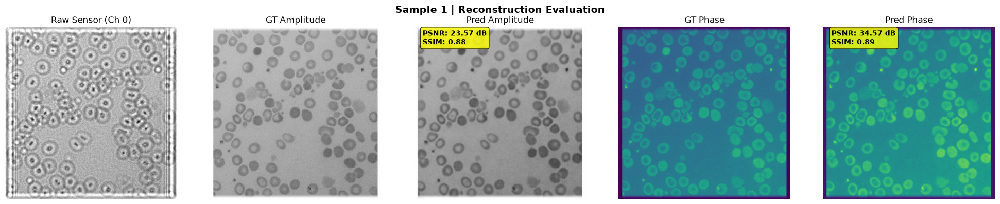

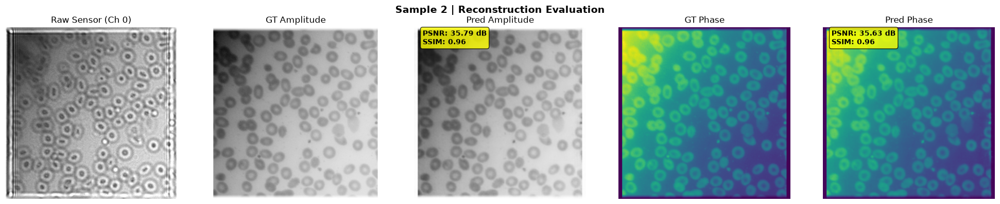

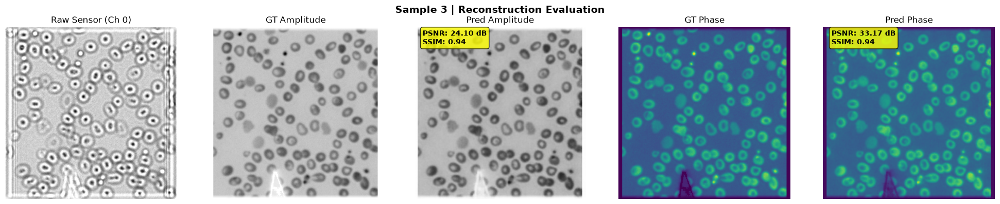

In [4]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt
from skimage.metrics import peak_signal_noise_ratio as compute_psnr
from skimage.metrics import structural_similarity as compute_ssim

def evaluate_and_visualize_predictions(
    model, 
    test_loader, 
    device='cuda', 
    checkpoint_path="/home/sakshi/Unet 3+ reconstruction/two_stage_decoupled_outputs/best_phase1_model.pth",
    num_samples_to_plot=4
):
    # 1. Load trained checkpoint weights
    print(f"Loading checkpoint from: {checkpoint_path}")
    checkpoint = torch.load(checkpoint_path, map_location=device)
    if isinstance(checkpoint, dict) and 'model_state_dict' in checkpoint:
        model.load_state_dict(checkpoint['model_state_dict'])
    else:
        model.load_state_dict(checkpoint)
    
    model.to(device)
    model.eval()
    print("Model loaded successfully in evaluation mode.")

    plotted_count = 0
    
    # 2. Iterate through test loader and perform inference
    with torch.no_grad():
        for batch_idx, (sensor_inputs_z, raw_sensor, target_amp, target_phase) in enumerate(test_loader):
            if plotted_count >= num_samples_to_plot:
                break
                
            sensor_inputs_z = sensor_inputs_z.to(device)
            
            # Forward pass to get predictions
            pred_amp, pred_phase = model(sensor_inputs_z)
            
            # Move tensors to CPU numpy for metric calculation and plotting
            b_size = sensor_inputs_z.shape[0]
            for i in range(b_size):
                if plotted_count >= num_samples_to_plot:
                    break
                
                raw_np = raw_sensor[i, 0].cpu().numpy()  # Channel 0 raw hologram
                gt_amp_np = target_amp[i, 0].cpu().numpy()
                pr_amp_np = pred_amp[i, 0].cpu().numpy()
                gt_phase_np = target_phase[i, 0].cpu().numpy()
                pr_phase_np = pred_phase[i, 0].cpu().numpy()
                
                # Compute Quantitative Metrics (PSNR & SSIM)
                # Amplitude metrics
                amp_psnr = compute_psnr(gt_amp_np, pr_amp_np, data_range=1.0)
                amp_ssim = compute_ssim(gt_amp_np, pr_amp_np, data_range=1.0)
                
                # Phase metrics (scaled to data range)
                p_min, p_max = gt_phase_np.min(), gt_phase_np.max()
                phase_range = max(float(p_max - p_min), 1e-5)
                phase_psnr = compute_psnr(gt_phase_np, pr_phase_np, data_range=phase_range)
                phase_ssim = compute_ssim(gt_phase_np, pr_phase_np, data_range=phase_range)

                # 3. Plotting the Comparison Grid
                fig, axes = plt.subplots(1, 5, figsize=(20, 4))
                fig.suptitle(f"Sample {plotted_count + 1} | Reconstruction Evaluation", fontsize=14, fontweight='bold')

                # Raw Sensor Hologram (Channel 0)
                axes[0].imshow(raw_np, cmap='gray')
                axes[0].set_title("Raw Sensor (Ch 0)")
                axes[0].axis('off')

                # Ground Truth Amplitude
                axes[1].imshow(gt_amp_np, cmap='gray', vmin=0, vmax=1)
                axes[1].set_title("GT Amplitude")
                axes[1].axis('off')

                # Predicted Amplitude with Metrics Badge
                im2 = axes[2].imshow(pr_amp_np, cmap='gray', vmin=0, vmax=1)
                axes[2].set_title("Pred Amplitude")
                axes[2].axis('off')
                axes[2].text(
                    0.05, 0.90, f"PSNR: {amp_psnr:.2f} dB\nSSIM: {amp_ssim:.2f}", 
                    transform=axes[2].transAxes, fontsize=10, fontweight='bold',
                    bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.8)
                )

                # Ground Truth Phase
                axes[3].imshow(gt_phase_np, cmap='viridis')
                axes[3].set_title("GT Phase")
                axes[3].axis('off')

                # Predicted Phase with Metrics Badge
                axes[4].imshow(pr_phase_np, cmap='viridis')
                axes[4].set_title("Pred Phase")
                axes[4].axis('off')
                axes[4].text(
                    0.05, 0.90, f"PSNR: {phase_psnr:.2f} dB\nSSIM: {phase_ssim:.2f}", 
                    transform=axes[4].transAxes, fontsize=10, fontweight='bold',
                    bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.8)
                )

                plt.tight_layout()
                plt.show()
                
                plotted_count += 1

# ============================================================================
# Execution Example
# ============================================================================
if __name__ == '__main__':
    # Ensure test_loader is available from your script execution
    if 'test_loader' in locals() and 'model' in locals():
        evaluate_and_visualize_predictions(
            model=model,
            test_loader=test_loader,
            device=device,
            checkpoint_path="/home/sakshi/Unet 3+ reconstruction/two_stage_decoupled_outputs/best_phase1_model.pth",
            num_samples_to_plot=3  # Change to plot more samples
        )
    else:
        print("Please ensure 'model' and 'test_loader' are initialized in your workspace.")

Loading checkpoint from: /home/sakshi/Unet 3+ reconstruction/two_stage_decoupled_outputs/final_phase2_model.pth
Model loaded successfully in evaluation mode.

-> Visualizing sample from dataset category: Anemic RBC


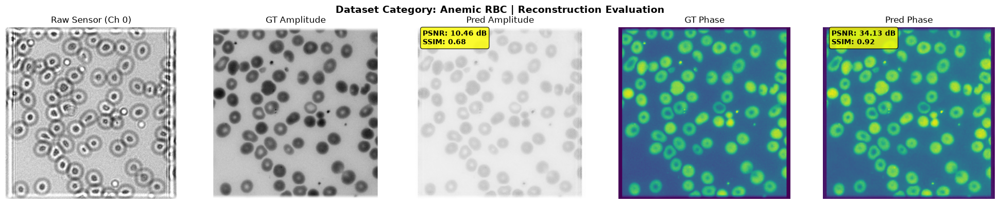

-> Visualizing sample from dataset category: Malaria


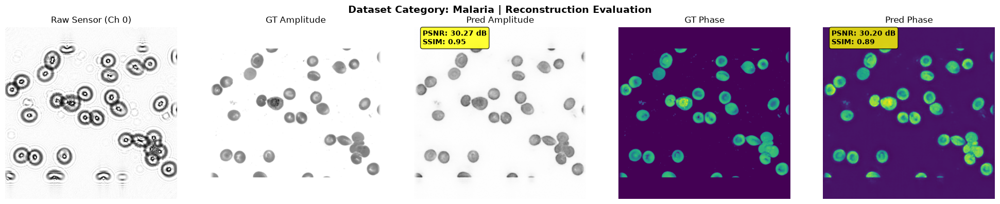

-> Visualizing sample from dataset category: Rouleaux


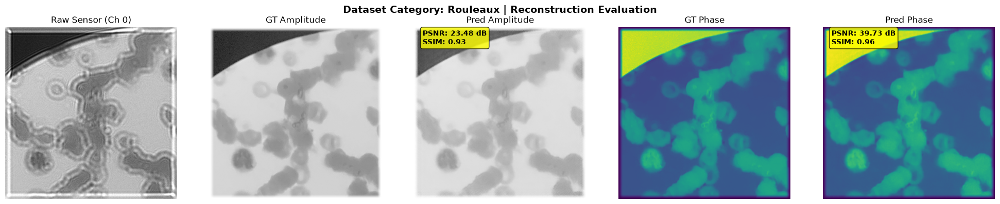

-> Visualizing sample from dataset category: Lung Cancer


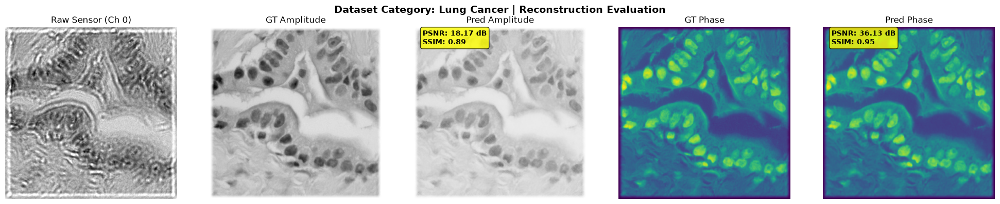

In [5]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt
from skimage.metrics import peak_signal_noise_ratio as compute_psnr
from skimage.metrics import structural_similarity as compute_ssim

def visualize_one_sample_per_dataset(
    model, 
    sensor_dirs, 
    dataset_names=None,
    device='cuda', 
    checkpoint_path="./two_stage_decoupled_outputs/final_phase2_model.pth"
):
    # 1. Load trained checkpoint weights
    print(f"Loading checkpoint from: {checkpoint_path}")
    checkpoint = torch.load(checkpoint_path, map_location=device)
    if isinstance(checkpoint, dict) and 'model_state_dict' in checkpoint:
        model.load_state_dict(checkpoint['model_state_dict'])
    else:
        model.load_state_dict(checkpoint)
    
    model.to(device)
    model.eval()
    print("Model loaded successfully in evaluation mode.\n")

    if dataset_names is None:
        dataset_names = [os.path.basename(os.path.normpath(d)) for d in sensor_dirs]

    # 2. Iterate through each dataset directory and extract the first sample
    with torch.no_grad():
        for name, s_dir in zip(dataset_names, sensor_dirs):
            if not os.path.exists(s_dir):
                print(f"Skipping [{name}]: Directory not found -> {s_dir}")
                continue
            
            # Instantiate dataset directly for this folder without augmentation
            ds = HologramHybridDataset(sensor_dir=s_dir, augment=False)
            if len(ds) == 0:
                print(f"Skipping [{name}]: No simulation files found.")
                continue
            
            print(f"-> Visualizing sample from dataset category: {name}")
            
            # Fetch the first sample (index 0)
            sensor_inputs_z, raw_sensor, target_amp, target_phase = ds[0]
            
            # Add batch dimension and move to device
            sensor_inputs_z_batch = sensor_inputs_z.unsqueeze(0).to(device)
            
            # Forward pass through UNet3+
            pred_amp, pred_phase = model(sensor_inputs_z_batch)
            
            # Extract numpy arrays for plotting and evaluation
            raw_np = raw_sensor[0].cpu().numpy()  # Channel 0 raw hologram
            gt_amp_np = target_amp[0].cpu().numpy()
            pr_amp_np = pred_amp[0, 0].cpu().numpy()
            gt_phase_np = target_phase[0].cpu().numpy()
            pr_phase_np = pred_phase[0, 0].cpu().numpy()
            
            # Compute Quantitative Metrics (PSNR & SSIM)
            amp_psnr = compute_psnr(gt_amp_np, pr_amp_np, data_range=1.0)
            amp_ssim = compute_ssim(gt_amp_np, pr_amp_np, data_range=1.0)
            
            p_min, p_max = gt_phase_np.min(), gt_phase_np.max()
            phase_range = max(float(p_max - p_min), 1e-5)
            phase_psnr = compute_psnr(gt_phase_np, pr_phase_np, data_range=phase_range)
            phase_ssim = compute_ssim(gt_phase_np, pr_phase_np, data_range=phase_range)

            # 3. Plotting the Comparison Grid
            fig, axes = plt.subplots(1, 5, figsize=(20, 4))
            fig.suptitle(f"Dataset Category: {name} | Reconstruction Evaluation", fontsize=14, fontweight='bold')

            # Raw Sensor Hologram (Channel 0)
            axes[0].imshow(raw_np, cmap='gray')
            axes[0].set_title("Raw Sensor (Ch 0)")
            axes[0].axis('off')

            # Ground Truth Amplitude
            axes[1].imshow(gt_amp_np, cmap='gray', vmin=0, vmax=1)
            axes[1].set_title("GT Amplitude")
            axes[1].axis('off')

            # Predicted Amplitude with Metrics Badge
            axes[2].imshow(pr_amp_np, cmap='gray', vmin=0, vmax=1)
            axes[2].set_title("Pred Amplitude")
            axes[2].axis('off')
            axes[2].text(
                0.05, 0.90, f"PSNR: {amp_psnr:.2f} dB\nSSIM: {amp_ssim:.2f}", 
                transform=axes[2].transAxes, fontsize=10, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.8)
            )

            # Ground Truth Phase
            axes[3].imshow(gt_phase_np, cmap='viridis')
            axes[3].set_title("GT Phase")
            axes[3].axis('off')

            # Predicted Phase with Metrics Badge
            axes[4].imshow(pr_phase_np, cmap='viridis')
            axes[4].set_title("Pred Phase")
            axes[4].axis('off')
            axes[4].text(
                0.05, 0.90, f"PSNR: {phase_psnr:.2f} dB\nSSIM: {phase_ssim:.2f}", 
                transform=axes[4].transAxes, fontsize=10, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.8)
            )

            plt.tight_layout()
            plt.show()

# ============================================================================
# Execution Block
# ============================================================================
if __name__ == '__main__':
    if 'model' in locals():
        base_dir = "/home/sakshi/Unet 3+ reconstruction"
        
        # Paths to your simulation .npz directories
        sensor_dirs = [
            os.path.join(base_dir, "Digital_twin_simulation/Anemic_RGB"),
            os.path.join(base_dir, "Digital_twin_simulation/Malaria_RGB"),
            os.path.join(base_dir, "Digital_twin_simulation/Rauleaux_RGB"),
            os.path.join(base_dir, "Digital_twin_simulation/Lung_cancer_RGB")
        ]
        dataset_names = ["Anemic RBC", "Malaria", "Rouleaux", "Lung Cancer"]
        
        visualize_one_sample_per_dataset(
            model=model,
            sensor_dirs=sensor_dirs,
            dataset_names=dataset_names,
            device=device,
            checkpoint_path=os.path.join(base_dir, "two_stage_decoupled_outputs/final_phase2_model.pth")
        )
    else:
        print("Please ensure 'model' is initialized in your workspace.")

In [5]:
best_phase2_ckpt, final_phase2_ckpt = execute_phase2_co_optimization(
    model=model,
    forward_model=forward_model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=10,                    # Short run to let physics refine the edges
    lr=1e-5,                     # Delicate fine-tuning learning rate
    device=device,
    checkpoint_dir=output_base_dir,
    resume_from_checkpoint=existing_checkpoint, # Points to your best_phase1_model.pth
    lambda_phys=0.3,             # Gentle physics weight to sharpen diffraction details
    lambda_freq=0.1,             # Fourier loss to target high-frequency details
    lambda_ssim=0.1,
    lambda_tv=0.001,
    lambda_supervise_anchor=0.7, # Strong anchor to keep the cell layouts locked in place
    patience=2                   # Stop early if validation plateaus
)

Successfully loaded checkpoint from '/home/sakshi/Unet 3+ reconstruction/two_stage_decoupled_outputs/best_phase1_model.pth' for Phase 2 fine-tuning.
=== STARTING PHASE 2: PHYSICS CO-OPTIMIZATION (Max 10 Epochs, Patience: 2) ===
  [Anchor Decay] lambda_supervise_anchor = 0.7000


Phase 2 | Epoch [1/10]: 100%|██████████| 1575/1575 [2:00:21<00:00,  4.59s/it, Loss=0.1662, Phys=0.0867] 


-> Phase 2 Epoch [1] | Train Loss: 0.1801 | Val Loss: 0.1820
[*] New best Phase 2 checkpoint saved (Val Loss: 0.1820)
  [Anchor Decay] lambda_supervise_anchor = 0.4900


Phase 2 | Epoch [2/10]: 100%|██████████| 1575/1575 [2:09:30<00:00,  4.93s/it, Loss=0.2302, Phys=0.0898] 


-> Phase 2 Epoch [2] | Train Loss: 0.1530 | Val Loss: 0.1550
[*] New best Phase 2 checkpoint saved (Val Loss: 0.1550)
  [Anchor Decay] lambda_supervise_anchor = 0.3430


...

-> Phase 2 Epoch [8] | Train Loss: 0.0840 | Val Loss: 0.0851
[*] New best Phase 2 checkpoint saved (Val Loss: 0.0851)
  [Anchor Decay] lambda_supervise_anchor = 0.1000


Phase 2 | Epoch [9/10]: 100%|██████████| 1575/1575 [1:00:25<00:00,  2.30s/it, Loss=0.0768, Phys=0.0244]


-> Phase 2 Epoch [9] | Train Loss: 0.0837 | Val Loss: 0.0849
[*] New best Phase 2 checkpoint saved (Val Loss: 0.0849)
  [Anchor Decay] lambda_supervise_anchor = 0.1000


Phase 2 | Epoch [10/10]: 100%|██████████| 1575/1575 [59:34<00:00,  2.27s/it, Loss=0.0818, Phys=0.0198] 


-> Phase 2 Epoch [10] | Train Loss: 0.0835 | Val Loss: 0.0848
[*] New best Phase 2 checkpoint saved (Val Loss: 0.0848)

Phase 2 training finished!


In [6]:
import os
import torch
import numpy as np
import json
from tqdm import tqdm
from skimage.metrics import peak_signal_noise_ratio as compute_psnr
from skimage.metrics import structural_similarity as compute_ssim

def evaluate_on_test_set(
    model, 
    test_loader, 
    device='cuda', 
    checkpoint_path="/home/sakshi/Unet 3+ reconstruction/two_stage_decoupled_outputs/best_phase2_model.pth",
    save_metrics_path="/home/sakshi/Unet 3+ reconstruction/two_stage_decoupled_outputs/test_evaluation_metrics.json"
):
    """
    Evaluates the trained model on the complete test data loader, 
    computing aggregate PSNR and SSIM metrics for amplitude and phase.
    """
    print(f"Loading checkpoint for test evaluation from: {checkpoint_path}")
    if os.path.exists(checkpoint_path):
        checkpoint = torch.load(checkpoint_path, map_location=device)
        if isinstance(checkpoint, dict) and 'model_state_dict' in checkpoint:
            model.load_state_dict(checkpoint['model_state_dict'])
        else:
            model.load_state_dict(checkpoint)
        print("Checkpoint successfully loaded.")
    else:
        print(f"Warning: Checkpoint path not found at {checkpoint_path}. Evaluating with current model weights.")
    
    model.to(device)
    model.eval()
    
    amp_psnrs = []
    amp_ssims = []
    phase_psnrs = []
    phase_ssims = []

    print("\n=== RUNNING QUANTITATIVE EVALUATION ON TEST SET ===")
    with torch.no_grad():
        for sensor_inputs_z, raw_sensor, target_amp, target_phase in tqdm(test_loader, desc="Evaluating Test Set"):
            sensor_inputs_z = sensor_inputs_z.to(device)
            
            # Forward pass through UNet3+
            pred_amp, pred_phase = model(sensor_inputs_z)
            
            b_size = sensor_inputs_z.shape[0]
            for i in range(b_size):
                gt_amp_np = target_amp[i, 0].cpu().numpy()
                pr_amp_np = pred_amp[i, 0].cpu().numpy()
                gt_phase_np = target_phase[i, 0].cpu().numpy()
                pr_phase_np = pred_phase[i, 0].cpu().numpy()
                
                # 1. Amplitude Quantitative Metrics
                a_psnr = compute_psnr(gt_amp_np, pr_amp_np, data_range=1.0)
                a_ssim = compute_ssim(gt_amp_np, pr_amp_np, data_range=1.0)
                amp_psnrs.append(a_psnr)
                amp_ssims.append(a_ssim)
                
                # 2. Phase Quantitative Metrics
                p_min, p_max = gt_phase_np.min(), gt_phase_np.max()
                phase_range = max(float(p_max - p_min), 1e-5)
                p_psnr = compute_psnr(gt_phase_np, pr_phase_np, data_range=phase_range)
                p_ssim = compute_ssim(gt_phase_np, pr_phase_np, data_range=phase_range)
                phase_psnrs.append(p_psnr)
                phase_ssims.append(p_ssim)

    # Aggregate statistical results
    avg_results = {
        "Amplitude_PSNR_Mean": float(np.mean(amp_psnrs)),
        "Amplitude_PSNR_Std": float(np.std(amp_psnrs)),
        "Amplitude_SSIM_Mean": float(np.mean(amp_ssims)),
        "Amplitude_SSIM_Std": float(np.std(amp_ssims)),
        "Phase_PSNR_Mean": float(np.mean(phase_psnrs)),
        "Phase_PSNR_Std": float(np.std(phase_psnrs)),
        "Phase_SSIM_Mean": float(np.mean(phase_ssims)),
        "Phase_SSIM_Std": float(np.std(phase_ssims)),
        "Total_Test_Samples": len(amp_psnrs)
    }

    # Print formatted summary table
    print("\n================ TEST SET PERFORMANCE SUMMARY ================")
    print(f"Total Evaluated Test Samples: {avg_results['Total_Test_Samples']}")
    print(f"Amplitude -> PSNR: {avg_results['Amplitude_PSNR_Mean']:.2f} ± {avg_results['Amplitude_PSNR_Std']:.2f} dB")
    print(f"             SSIM: {avg_results['Amplitude_SSIM_Mean']:.4f} ± {avg_results['Amplitude_SSIM_Std']:.4f}")
    print(f"Phase     -> PSNR: {avg_results['Phase_PSNR_Mean']:.2f} ± {avg_results['Phase_PSNR_Std']:.2f} dB")
    print(f"             SSIM: {avg_results['Phase_SSIM_Mean']:.4f} ± {avg_results['Phase_SSIM_Std']:.4f}")
    print("================================================================")

    # Save metrics report to JSON
    if save_metrics_path:
        os.makedirs(os.path.dirname(save_metrics_path), exist_ok=True)
        with open(save_metrics_path, 'w') as f:
            json.dump(avg_results, f, indent=4)
        print(f"Detailed metrics report saved to: {save_metrics_path}")

    return avg_results

# ============================================================================
# Execution Block
# ============================================================================
if __name__ == '__main__':
    if 'test_loader' in locals() and 'model' in locals():
        test_metrics = evaluate_on_test_set(
            model=model,
            test_loader=test_loader,
            device=device,
            checkpoint_path="/home/sakshi/Unet 3+ reconstruction/two_stage_decoupled_outputs/best_phase2_model.pth",
            save_metrics_path="/home/sakshi/Unet 3+ reconstruction/two_stage_decoupled_outputs/test_evaluation_metrics.json"
        )
    else:
        print("Please ensure 'model' and 'test_loader' are initialized in your workspace before running.")

Loading checkpoint for test evaluation from: /home/sakshi/Unet 3+ reconstruction/two_stage_decoupled_outputs/best_phase2_model.pth
Checkpoint successfully loaded.

=== RUNNING QUANTITATIVE EVALUATION ON TEST SET ===


Evaluating Test Set: 100%|██████████| 450/450 [04:23<00:00,  1.71it/s]


================ TEST SET PERFORMANCE SUMMARY ================
Total Evaluated Test Samples: 900
Amplitude -> PSNR: 20.94 ± 7.29 dB
             SSIM: 0.8586 ± 0.1049
Phase     -> PSNR: 33.59 ± 3.76 dB
             SSIM: 0.9315 ± 0.0346
Detailed metrics report saved to: /home/sakshi/Unet 3+ reconstruction/two_stage_decoupled_outputs/test_evaluation_metrics.json


Loading checkpoint for test visualization from: /home/sakshi/Unet 3+ reconstruction/two_stage_decoupled_outputs/final_phase2_model.pth
Checkpoint loaded successfully.

-> Visualizing test sample from category: Anemic RBC (Test pool size: 200)


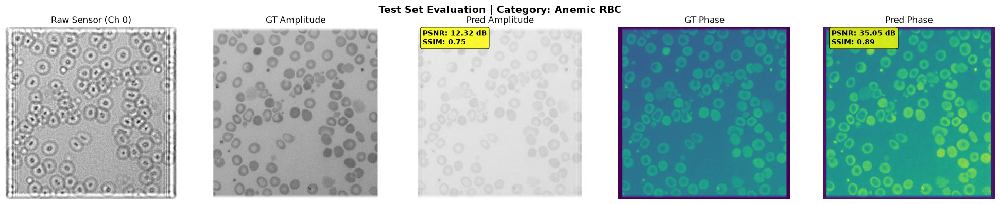

-> Visualizing test sample from category: Malaria (Test pool size: 200)


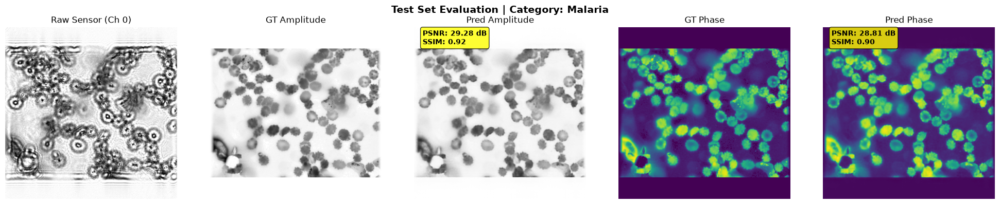

-> Visualizing test sample from category: Rouleaux (Test pool size: 200)


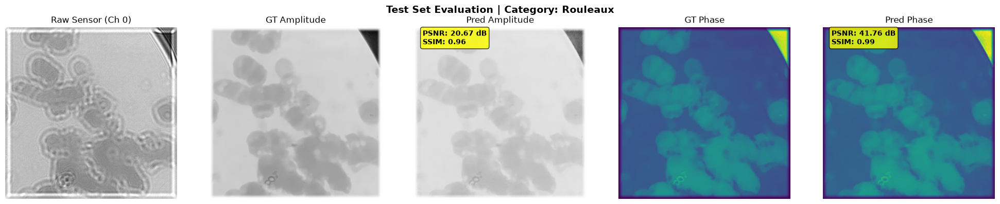

-> Visualizing test sample from category: Lung Cancer (Test pool size: 300)


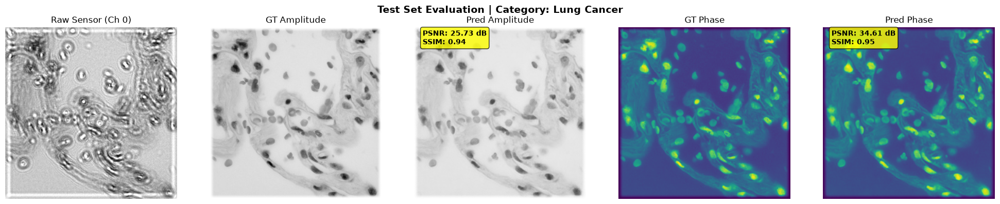

In [6]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import random_split
from skimage.metrics import peak_signal_noise_ratio as compute_psnr
from skimage.metrics import structural_similarity as compute_ssim

def visualize_one_test_sample_per_category(
    model, 
    sensor_dirs, 
    dataset_names=None,
    device='cuda', 
    checkpoint_path="./two_stage_decoupled_outputs/final_phase1_model.pth",
    train_split=0.7,
    val_split=0.1
):
    """
    Pulls and visualizes one test sample from each individual dataset folder 
    using the identical random split configuration as the data loader.
    """
    print(f"Loading checkpoint for test visualization from: {checkpoint_path}")
    if os.path.exists(checkpoint_path):
        checkpoint = torch.load(checkpoint_path, map_location=device)
        if isinstance(checkpoint, dict) and 'model_state_dict' in checkpoint:
            model.load_state_dict(checkpoint['model_state_dict'])
        else:
            model.load_state_dict(checkpoint)
        print("Checkpoint loaded successfully.\n")
    else:
        print(f"Warning: Checkpoint not found at {checkpoint_path}. Using current model weights.")
    
    model.to(device)
    model.eval()

    if dataset_names is None:
        dataset_names = [os.path.basename(os.path.normpath(d)) for d in sensor_dirs]

    with torch.no_grad():
        for name, s_dir in zip(dataset_names, sensor_dirs):
            if not os.path.exists(s_dir):
                print(f"Skipping [{name}]: Directory not found -> {s_dir}")
                continue
            
            # 1. Initialize dataset for this specific folder without augmentation
            ds = HologramHybridDataset(sensor_dir=s_dir, augment=False)
            n_total = len(ds)
            if n_total == 0:
                print(f"Skipping [{name}]: No simulation files found.")
                continue
                
            n_train = int(train_split * n_total)
            n_val = int(val_split * n_total)
            n_test = n_total - n_train - n_val
            
            # 2. Replicate the exact train/val/test split configuration
            _, _, test_subset = random_split(
                ds, [n_train, n_val, n_test], 
                generator=torch.Generator().manual_seed(42)
            )
            
            if len(test_subset) == 0:
                print(f"Skipping [{name}]: Test split is empty.")
                continue

            print(f"-> Visualizing test sample from category: {name} (Test pool size: {len(test_subset)})")
            
            # 3. Pull the first sample from this category's test split
            sensor_inputs_z, raw_sensor, target_amp, target_phase = test_subset[0]
            
            # Add batch dimension and move to device
            sensor_inputs_z_batch = sensor_inputs_z.unsqueeze(0).to(device)
            
            # Forward pass through UNet3+
            pred_amp, pred_phase = model(sensor_inputs_z_batch)
            
            # Extract numpy arrays
            raw_np = raw_sensor[0].cpu().numpy()  # Channel 0 raw hologram
            gt_amp_np = target_amp[0].cpu().numpy()
            pr_amp_np = pred_amp[0, 0].cpu().numpy()
            gt_phase_np = target_phase[0].cpu().numpy()
            pr_phase_np = pred_phase[0, 0].cpu().numpy()
            
            # Compute Quantitative Metrics
            amp_psnr = compute_psnr(gt_amp_np, pr_amp_np, data_range=1.0)
            amp_ssim = compute_ssim(gt_amp_np, pr_amp_np, data_range=1.0)
            
            p_min, p_max = gt_phase_np.min(), gt_phase_np.max()
            phase_range = max(float(p_max - p_min), 1e-5)
            phase_psnr = compute_psnr(gt_phase_np, pr_phase_np, data_range=phase_range)
            phase_ssim = compute_ssim(gt_phase_np, pr_phase_np, data_range=phase_range)

            # 4. Plotting the 5-panel comparison grid
            fig, axes = plt.subplots(1, 5, figsize=(20, 4))
            fig.suptitle(f"Test Set Evaluation | Category: {name}", fontsize=14, fontweight='bold')

            # Raw Sensor Hologram
            axes[0].imshow(raw_np, cmap='gray')
            axes[0].set_title("Raw Sensor (Ch 0)")
            axes[0].axis('off')

            # Ground Truth Amplitude
            axes[1].imshow(gt_amp_np, cmap='gray', vmin=0, vmax=1)
            axes[1].set_title("GT Amplitude")
            axes[1].axis('off')

            # Predicted Amplitude with Metrics Badge
            axes[2].imshow(pr_amp_np, cmap='gray', vmin=0, vmax=1)
            axes[2].set_title("Pred Amplitude")
            axes[2].axis('off')
            axes[2].text(
                0.05, 0.90, f"PSNR: {amp_psnr:.2f} dB\nSSIM: {amp_ssim:.2f}", 
                transform=axes[2].transAxes, fontsize=10, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.8)
            )

            # Ground Truth Phase
            axes[3].imshow(gt_phase_np, cmap='viridis')
            axes[3].set_title("GT Phase")
            axes[3].axis('off')

            # Predicted Phase with Metrics Badge
            axes[4].imshow(pr_phase_np, cmap='viridis')
            axes[4].set_title("Pred Phase")
            axes[4].axis('off')
            axes[4].text(
                0.05, 0.90, f"PSNR: {phase_psnr:.2f} dB\nSSIM: {phase_ssim:.2f}", 
                transform=axes[4].transAxes, fontsize=10, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.8)
            )

            plt.tight_layout()
            plt.show()

# ============================================================================
# Execution Block
# ============================================================================
if __name__ == '__main__':
    if 'model' in locals():
        base_dir = "/home/sakshi/Unet 3+ reconstruction"
        
        sensor_dirs = [
            os.path.join(base_dir, "Digital_twin_simulation/Anemic_RGB"),
            os.path.join(base_dir, "Digital_twin_simulation/Malaria_RGB"),
            os.path.join(base_dir, "Digital_twin_simulation/Rauleaux_RGB"),
            os.path.join(base_dir, "Digital_twin_simulation/Lung_cancer_RGB")
        ]
        dataset_names = ["Anemic RBC", "Malaria", "Rouleaux", "Lung Cancer"]
        
        visualize_one_test_sample_per_category(
            model=model,
            sensor_dirs=sensor_dirs,
            dataset_names=dataset_names,
            device=device,
            checkpoint_path=os.path.join(base_dir, "two_stage_decoupled_outputs/final_phase2_model.pth"),
            train_split=0.7,
            val_split=0.1
        )
    else:
        print("Please ensure 'model' is initialized in your workspace.")

Loading checkpoint from: /home/sakshi/Unet 3+ reconstruction/two_stage_decoupled_outputs/final_phase2_model.pth
Checkpoint loaded successfully.

Found 1 unseen file(s) to evaluate.
-> Processing unseen sample: healthy_RBC_0009_data.npz


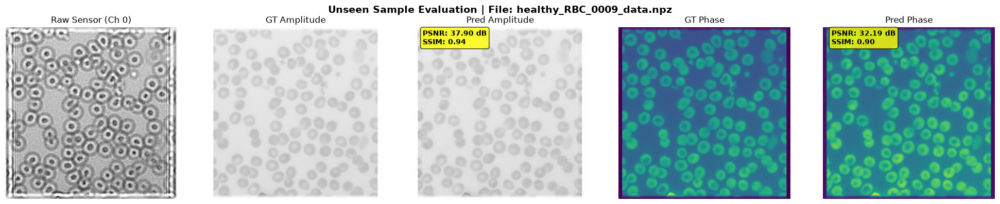

In [4]:
import os
import glob
import torch
import numpy as np
import matplotlib.pyplot as plt
from skimage.metrics import peak_signal_noise_ratio as compute_psnr
from skimage.metrics import structural_similarity as compute_ssim

def visualize_custom_unseen_samples(
    model, 
    test_path, 
    device='cuda', 
    checkpoint_path="./two_stage_decoupled_outputs/final_phase2_model.pth"
):
    """
    Visualizes reconstruction results for custom unseen test paths 
    (supports both a single .npz file path or a folder containing .npz files).
    """
    print(f"Loading checkpoint from: {checkpoint_path}")
    if os.path.exists(checkpoint_path):
        checkpoint = torch.load(checkpoint_path, map_location=device)
        if isinstance(checkpoint, dict) and 'model_state_dict' in checkpoint:
            model.load_state_dict(checkpoint['model_state_dict'])
        else:
            model.load_state_dict(checkpoint)
        print("Checkpoint loaded successfully.\n")
    else:
        print(f"Warning: Checkpoint not found at {checkpoint_path}. Using current model weights.")
    
    model.to(device)
    model.eval()

    # Resolve whether the input is a single file or a directory
    if os.path.isfile(test_path) and test_path.endswith('.npz'):
        file_list = [test_path]
    elif os.path.isdir(test_path):
        file_list = sorted(glob.glob(os.path.join(test_path, "*.npz")))
    else:
        print(f"Error: Invalid path provided -> {test_path}")
        return

    if len(file_list) == 0:
        print(f"No .npz files found at: {test_path}")
        return

    print(f"Found {len(file_list)} unseen file(s) to evaluate.")

    with torch.no_grad():
        for file_path in file_list:
            file_name = os.path.basename(file_path)
            print(f"-> Processing unseen sample: {file_name}")
            
            data = np.load(file_path)
            if 'input_tensor' not in data:
                print(f"  [!] Error: 'input_tensor' missing in {file_name}. Available keys: {list(data.keys())}")
                continue
            
            sensor_tensor = torch.from_numpy(data['input_tensor']).float()
            
            # Z-normalize sensor input for UNet3+
            sensor_inputs_z = (sensor_tensor - sensor_tensor.mean(dim=(-2, -1), keepdim=True)) / \
                              (sensor_tensor.std(dim=(-2, -1), keepdim=True) + 1e-8)
            
            # Add batch dimension and move to device
            sensor_inputs_z_batch = sensor_inputs_z.unsqueeze(0).to(device)
            
            # Forward pass through model
            pred_amp, pred_phase = model(sensor_inputs_z_batch)
            
            raw_np = sensor_tensor[0].cpu().numpy()  # Channel 0 raw hologram preview
            pr_amp_np = pred_amp[0, 0].cpu().numpy()
            pr_phase_np = pred_phase[0, 0].cpu().numpy()
            
            # Check if ground truth is present in the .npz file
            has_gt = 'target_amp' in data or 'amplitude' in data
            
            if has_gt:
                gt_amp_np = data.get('target_amp', data.get('amplitude'))
                gt_phase_np = data.get('target_phase', data.get('phase'))
                
                # Compute quantitative metrics
                amp_psnr = compute_psnr(gt_amp_np, pr_amp_np, data_range=1.0)
                amp_ssim = compute_ssim(gt_amp_np, pr_amp_np, data_range=1.0)
                
                p_min, p_max = gt_phase_np.min(), gt_phase_np.max()
                phase_range = max(float(p_max - p_min), 1e-5)
                phase_psnr = compute_psnr(gt_phase_np, pr_phase_np, data_range=phase_range)
                phase_ssim = compute_ssim(gt_phase_np, pr_phase_np, data_range=phase_range)

                # 5-Panel Plot (With Ground Truth)
                fig, axes = plt.subplots(1, 5, figsize=(20, 4))
                fig.suptitle(f"Unseen Sample Evaluation | File: {file_name}", fontsize=14, fontweight='bold')

                axes[0].imshow(raw_np, cmap='gray')
                axes[0].set_title("Raw Sensor (Ch 0)")
                axes[0].axis('off')

                axes[1].imshow(gt_amp_np, cmap='gray', vmin=0, vmax=1)
                axes[1].set_title("GT Amplitude")
                axes[1].axis('off')

                axes[2].imshow(pr_amp_np, cmap='gray', vmin=0, vmax=1)
                axes[2].set_title("Pred Amplitude")
                axes[2].axis('off')
                axes[2].text(
                    0.05, 0.90, f"PSNR: {amp_psnr:.2f} dB\nSSIM: {amp_ssim:.2f}", 
                    transform=axes[2].transAxes, fontsize=10, fontweight='bold',
                    bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.8)
                )

                axes[3].imshow(gt_phase_np, cmap='viridis')
                axes[3].set_title("GT Phase")
                axes[3].axis('off')

                axes[4].imshow(pr_phase_np, cmap='viridis')
                axes[4].set_title("Pred Phase")
                axes[4].axis('off')
                axes[4].text(
                    0.05, 0.90, f"PSNR: {phase_psnr:.2f} dB\nSSIM: {phase_ssim:.2f}", 
                    transform=axes[4].transAxes, fontsize=10, fontweight='bold',
                    bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.8)
                )
            else:
                # 3-Panel Plot (Inference Only / Real Experimental Data)
                fig, axes = plt.subplots(1, 3, figsize=(15, 4))
                fig.suptitle(f"Unseen Experimental Sample | File: {file_name}", fontsize=14, fontweight='bold')

                axes[0].imshow(raw_np, cmap='gray')
                axes[0].set_title("Raw Sensor (Ch 0)")
                axes[0].axis('off')

                axes[1].imshow(pr_amp_np, cmap='gray', vmin=0, vmax=1)
                axes[1].set_title("Predicted Amplitude")
                axes[1].axis('off')

                axes[2].imshow(pr_phase_np, cmap='viridis')
                axes[2].set_title("Predicted Phase")
                axes[2].axis('off')

            plt.tight_layout()
            plt.show()

# ============================================================================
# Execution Block (Provide your custom path here)
# ============================================================================
if __name__ == '__main__':
    if 'model' in locals():
        # Option A: Path to a single specific .npz file
        # CUSTOM_PATH = "/home/sakshi/Unet 3+ reconstruction/Malaria_RGB/malaria_sample_01_data.npz"
        
        # Option B: Path to a folder containing multiple unseen .npz files
        CUSTOM_PATH = "/home/sakshi/Unet 3+ reconstruction/Digital_twin_simulation/Test_gen/Healthy_Images/healthy_RBC_0009_data.npz"
        
        visualize_custom_unseen_samples(
            model=model,
            test_path=CUSTOM_PATH,
            device=device,
            checkpoint_path="/home/sakshi/Unet 3+ reconstruction/two_stage_decoupled_outputs/final_phase2_model.pth"
        )
    else:
        print("Please ensure 'model' is initialized in your workspace.")

Running Digital Twin Generalization Visualizer on: cuda
>>> SUCCESS: New UNet3Plus architecture loaded with UN-FROZEN gradients! <<<
Loading Phase 2 checkpoint for Digital Twin OOD Evaluation from:
-> /home/sakshi/Unet 3+ reconstruction/two_stage_decoupled_outputs/final_phase2_model.pth
Phase 2 Checkpoint loaded successfully.

-> Rendering Digital Twin OOD Sample for: Colorectal Cancer (Total available: 100)


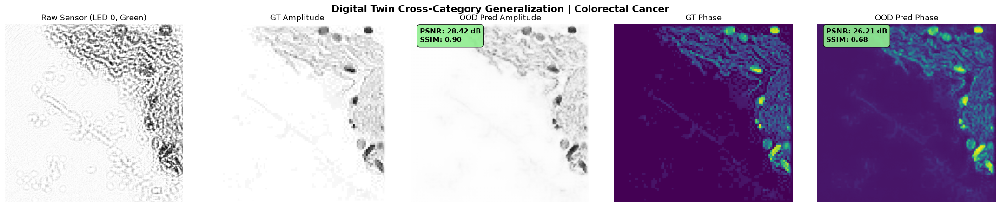

-> Rendering Digital Twin OOD Sample for: Healthy Blood Cells (Total available: 294)


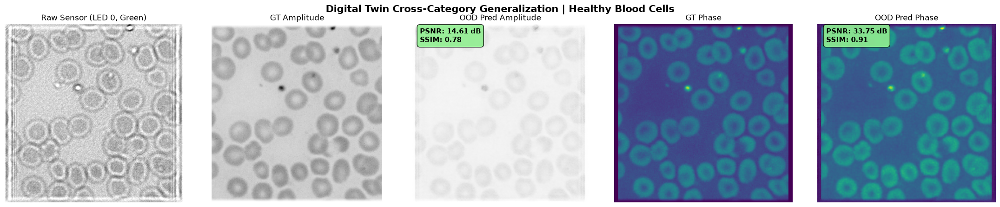

-> Rendering Digital Twin OOD Sample for: Pap Smear (Total available: 779)


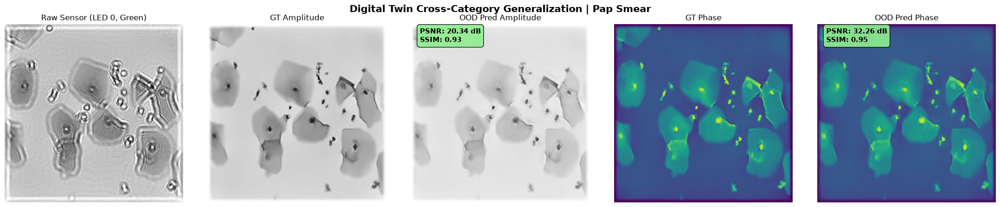

In [3]:
import os
import glob
import torch
import numpy as np
import matplotlib.pyplot as plt
import torchvision.transforms.functional as TF
from torch.utils.data import Dataset
from skimage.metrics import peak_signal_noise_ratio as compute_psnr
from skimage.metrics import structural_similarity as compute_ssim

# ============================================================================
# Digital Twin Dataset Loader (12-Channel)
# ============================================================================
class HologramHybridDataset(Dataset):
    def __init__(self, sensor_dir, crop_size=512):
        self.sensor_dir = sensor_dir
        self.crop_size = crop_size
        self.sensor_files = sorted([
            f for f in glob.glob(os.path.join(sensor_dir, "*.npz")) 
            if "scatterer_reference" not in os.path.basename(f)
        ])
        assert len(self.sensor_files) > 0, f"No simulation files found in {self.sensor_dir}!"

    def __len__(self):
        return len(self.sensor_files)

    def __getitem__(self, idx):
        s_path = self.sensor_files[idx]
        sensor_data = np.load(s_path)
        
        # Load the 12-channel tensor (4 LEDs x 3 Wavelengths)
        sensor_tensor = torch.from_numpy(sensor_data['input_tensor']).float()

        target_amp = torch.from_numpy(sensor_data.get('target_amp', sensor_data.get('amplitude', np.zeros((512, 512))))).float().unsqueeze(0)
        target_phase = torch.from_numpy(sensor_data.get('target_phase', sensor_data.get('phase', np.zeros((512, 512))))).float().unsqueeze(0)

        # Normalize Amplitude
        amp_min = target_amp.min()
        amp_max = target_amp.max()
        if amp_max - amp_min > 1e-8:
            target_amp = (target_amp - amp_min) / (amp_max - amp_min)
        else:
            target_amp = torch.zeros_like(target_amp)

        # Wrap Phase
        target_phase = torch.atan2(torch.sin(target_phase), torch.cos(target_phase))

        # Center Crop if necessary
        if sensor_tensor.shape[-1] != self.crop_size or sensor_tensor.shape[-2] != self.crop_size:
            sensor_tensor = TF.center_crop(sensor_tensor, [self.crop_size, self.crop_size])
            target_amp = TF.center_crop(target_amp, [self.crop_size, self.crop_size])
            target_phase = TF.center_crop(target_phase, [self.crop_size, self.crop_size])

        raw_sensor = sensor_tensor.clone()

        # Channel-wise Z-score normalization across the 12 channels
        sensor_inputs_z = (sensor_tensor - sensor_tensor.mean(dim=(-2, -1), keepdim=True)) / \
                          (sensor_tensor.std(dim=(-2, -1), keepdim=True) + 1e-8)

        return sensor_inputs_z, raw_sensor, target_amp, target_phase

# ============================================================================
# Visualization Function
# ============================================================================
def visualize_digital_twin_ood_generalization(
    model, 
    ood_sensor_dirs, 
    dataset_names=None,
    device='cuda', 
    checkpoint_path="/home/sakshi/Unet 3+ reconstruction/two_stage_decoupled_outputs/final_phase2_model.pth"
):
    print(f"Loading Phase 2 checkpoint for Digital Twin OOD Evaluation from:\n-> {checkpoint_path}")
    if os.path.exists(checkpoint_path):
        checkpoint = torch.load(checkpoint_path, map_location=device)
        if isinstance(checkpoint, dict) and 'model_state_dict' in checkpoint:
            model.load_state_dict(checkpoint['model_state_dict'])
        else:
            model.load_state_dict(checkpoint)
        print("Phase 2 Checkpoint loaded successfully.\n")
    else:
        print(f"Error: Checkpoint not found at {checkpoint_path}.")
        return
    
    model.to(device)
    model.eval()

    if dataset_names is None:
        dataset_names = [os.path.basename(os.path.normpath(d)) for d in ood_sensor_dirs]

    with torch.no_grad():
        for name, s_dir in zip(dataset_names, ood_sensor_dirs):
            if not os.path.exists(s_dir):
                print(f"Skipping [{name}]: Directory not found -> {s_dir}")
                continue
            
            # Load the entire unseen dataset using the 12-channel loader
            ds = HologramHybridDataset(sensor_dir=s_dir, crop_size=512)
            if len(ds) == 0:
                print(f"Skipping [{name}]: No .npz files found in directory.")
                continue

            print(f"-> Rendering Digital Twin OOD Sample for: {name} (Total available: {len(ds)})")
            
            # Pull the first sample from this unseen dataset
            sensor_inputs_z, raw_sensor, target_amp, target_phase = ds[0]
            
            # Add batch dimension
            sensor_inputs_z_batch = sensor_inputs_z.unsqueeze(0).to(device)
            
            # Forward pass
            pred_amp, pred_phase = model(sensor_inputs_z_batch)
            
            # Convert tensors to numpy
            # For 12 channels (4 LEDs x RGB), index 4 is typically Green (532nm) from LED 0
            raw_np = raw_sensor[4].cpu().numpy()  
            gt_amp_np = target_amp[0].cpu().numpy()
            pr_amp_np = pred_amp[0, 0].cpu().numpy()
            gt_phase_np = target_phase[0].cpu().numpy()
            pr_phase_np = pred_phase[0, 0].cpu().numpy()
            
            # Compute Quantitative Metrics
            amp_psnr = compute_psnr(gt_amp_np, pr_amp_np, data_range=1.0)
            amp_ssim = compute_ssim(gt_amp_np, pr_amp_np, data_range=1.0)
            
            phase_range = max(float(gt_phase_np.max() - gt_phase_np.min()), 1e-5)
            phase_psnr = compute_psnr(gt_phase_np, pr_phase_np, data_range=phase_range)
            phase_ssim = compute_ssim(gt_phase_np, pr_phase_np, data_range=phase_range)

            # Plotting 5-Panel Grid
            fig, axes = plt.subplots(1, 5, figsize=(22, 4.5))
            fig.suptitle(f"Digital Twin Cross-Category Generalization | {name}", fontsize=15, fontweight='bold')

            axes[0].imshow(raw_np, cmap='gray')
            axes[0].set_title("Raw Sensor (LED 0, Green)")
            axes[0].axis('off')

            axes[1].imshow(gt_amp_np, cmap='gray', vmin=0, vmax=1)
            axes[1].set_title("GT Amplitude")
            axes[1].axis('off')

            axes[2].imshow(pr_amp_np, cmap='gray', vmin=0, vmax=1)
            axes[2].set_title("OOD Pred Amplitude")
            axes[2].axis('off')
            axes[2].text(
                0.05, 0.90, f"PSNR: {amp_psnr:.2f} dB\nSSIM: {amp_ssim:.2f}", 
                transform=axes[2].transAxes, fontsize=11, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.4', facecolor='lightgreen', alpha=0.9)
            )

            axes[3].imshow(gt_phase_np, cmap='viridis')
            axes[3].set_title("GT Phase")
            axes[3].axis('off')

            axes[4].imshow(pr_phase_np, cmap='viridis')
            axes[4].set_title("OOD Pred Phase")
            axes[4].axis('off')
            axes[4].text(
                0.05, 0.90, f"PSNR: {phase_psnr:.2f} dB\nSSIM: {phase_ssim:.2f}", 
                transform=axes[4].transAxes, fontsize=11, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.4', facecolor='lightgreen', alpha=0.9)
            )

            plt.tight_layout()
            plt.show()

# ============================================================================
# Execution Block
# ============================================================================
if __name__ == '__main__':
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Running Digital Twin Generalization Visualizer on: {device}")

    # Ensure the model architecture matches your 12-channel Digital Twin training
    # (Assuming UNet3Plus is already defined in your notebook/script)
    model = UNet3Plus(in_channels=12, out_channels=2).to(device)

    base_dir = "/home/sakshi/Unet 3+ reconstruction"
    
    # Unseen validation datasets generated by the Digital Twin simulation
    ood_sensor_dirs = [
        os.path.join(base_dir, "Digital_twin_simulation/Test_gen/Extracted_Images"),
        os.path.join(base_dir, "Digital_twin_simulation/Test_gen/Healthy_Images"),
        os.path.join(base_dir, "Digital_twin_simulation/Test_gen/NILM")
    ]
    
    # Display names for the plots
    dataset_names = ["Colorectal Cancer", "Healthy Blood Cells", "Pap Smear"]

    visualize_digital_twin_ood_generalization(
        model=model,
        ood_sensor_dirs=ood_sensor_dirs,
        dataset_names=dataset_names,
        device=device,
        checkpoint_path=os.path.join(base_dir, "two_stage_decoupled_outputs/final_phase2_model.pth")
    )

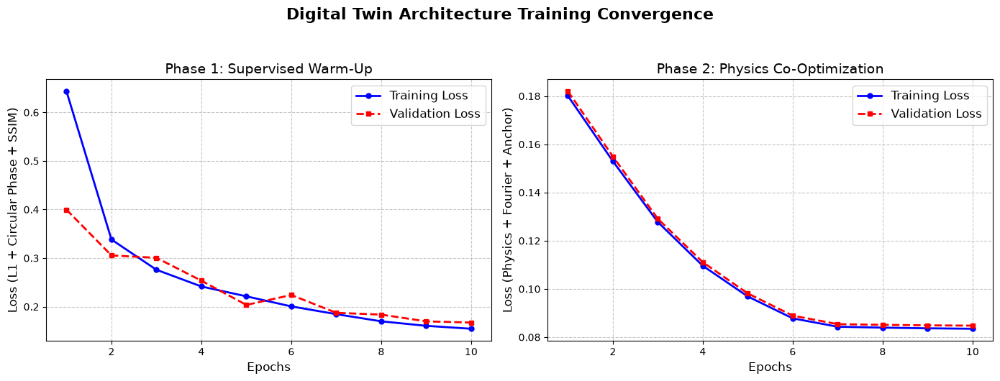

In [7]:
import os
import json
import matplotlib.pyplot as plt

def plot_two_stage_training_history(phase1_path, phase2_path):
    """
    Reads the JSON history files from Phase 1 and Phase 2 
    and plots them side-by-side for publication.
    """
    # 1. Safely load the JSON files
    try:
        with open(phase1_path, 'r') as f:
            history1 = json.load(f)
    except FileNotFoundError:
        print(f"Error: Phase 1 history not found at {phase1_path}")
        return

    try:
        with open(phase2_path, 'r') as f:
            history2 = json.load(f)
    except FileNotFoundError:
        print(f"Error: Phase 2 history not found at {phase2_path}")
        return

    # Extract data lists
    epochs1 = range(1, len(history1['train_loss']) + 1)
    train_loss1, val_loss1 = history1['train_loss'], history1['val_loss']

    epochs2 = range(1, len(history2['train_loss']) + 1)
    train_loss2, val_loss2 = history2['train_loss'], history2['val_loss']

    # 2. Setup the Plot Canvas (1 row, 2 columns)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle('Digital Twin Architecture Training Convergence', fontsize=16, fontweight='bold', y=1.05)

    # ---------------------------------------------------------
    # Subplot 1: Phase 1 (Supervised Warm-up)
    # ---------------------------------------------------------
    axes[0].plot(epochs1, train_loss1, 'b-o', label='Training Loss', linewidth=2, markersize=5)
    axes[0].plot(epochs1, val_loss1, 'r--s', label='Validation Loss', linewidth=2, markersize=5)
    axes[0].set_title('Phase 1: Supervised Warm-Up', fontsize=14)
    axes[0].set_xlabel('Epochs', fontsize=12)
    axes[0].set_ylabel('Loss (L1 + Circular Phase + SSIM)', fontsize=12)
    axes[0].grid(True, linestyle='--', alpha=0.7)
    axes[0].legend(fontsize=12)

    # ---------------------------------------------------------
    # Subplot 2: Phase 2 (Physics Co-Optimization)
    # ---------------------------------------------------------
    axes[1].plot(epochs2, train_loss2, 'b-o', label='Training Loss', linewidth=2, markersize=5)
    axes[1].plot(epochs2, val_loss2, 'r--s', label='Validation Loss', linewidth=2, markersize=5)
    axes[1].set_title('Phase 2: Physics Co-Optimization', fontsize=14)
    axes[1].set_xlabel('Epochs', fontsize=12)
    axes[1].set_ylabel('Loss (Physics + Fourier + Anchor)', fontsize=12)
    axes[1].grid(True, linestyle='--', alpha=0.7)
    axes[1].legend(fontsize=12)

    # 3. Final Formatting & Display
    plt.tight_layout()
    plt.show()

# ============================================================================
# Execution Block
# ============================================================================
# ============================================================================
# Execution Block (Corrected for Main Training Run)
# ============================================================================
if __name__ == '__main__':
    # Point directly to your main training outputs folder
    base_dir = "/home/sakshi/Unet 3+ reconstruction/two_stage_decoupled_outputs"
    
    # Notice we removed the "phase1" and "phase2" subfolders from the paths
    phase1_json = os.path.join(base_dir, "phase1_history.json")
    phase2_json = os.path.join(base_dir, "phase2_history.json")
    
    # Generate the plot
    plot_two_stage_training_history(phase1_json, phase2_json)